In [ ]:
!pip install numpy pandas matplotlib seaborn scikit-learn tensorflow

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Dense, Flatten, Dropout, BatchNormalization, Reshape, LSTM
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical

In [ ]:
from google.colab import files
uploaded = files.upload()

# Chargement du dataset
df = pd.read_csv("dataset_phishing.csv")

Saving dataset_phishing.csv to dataset_phishing.csv


In [ ]:
# Nettoyage des données
df = df.drop(columns=['url'])  # Suppression de la colonne non pertinente
df['status'] = df['status'].map({'legitimate': 0, 'phishing': 1})

In [ ]:
df.shape

(11430, 88)

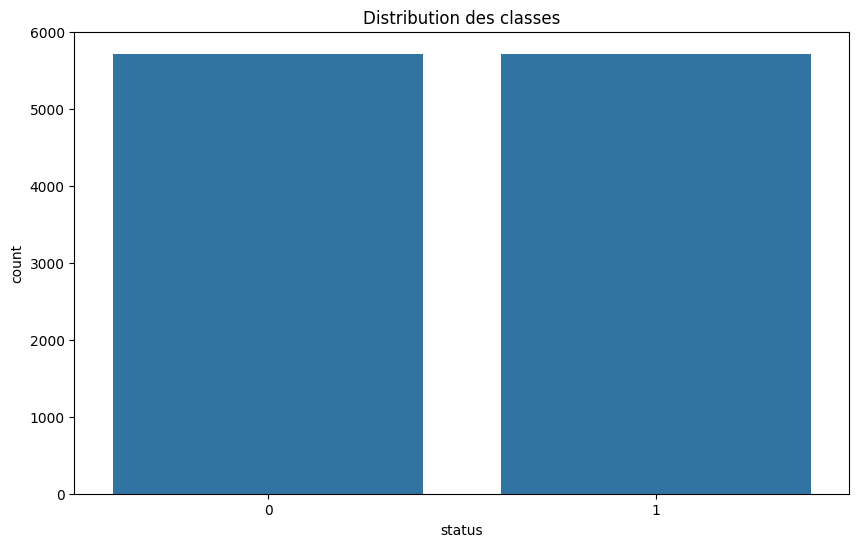

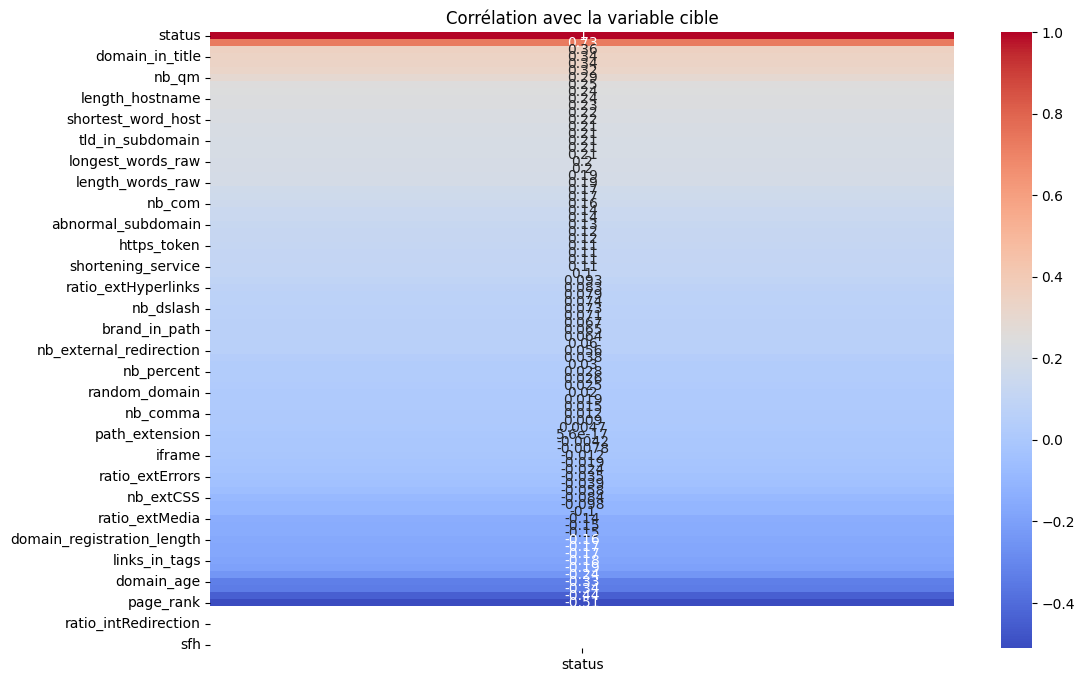

In [ ]:
# Étape 2: Analyse exploratoire (EDA)
# ---------------------------------------------------
plt.figure(figsize=(10, 6))
sns.countplot(x='status', data=df)
plt.title('Distribution des classes')
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr()[['status']].sort_values('status', ascending=False),
            annot=True, cmap='coolwarm')
plt.title('Corrélation avec la variable cible')
plt.show()


In [ ]:
plt.figure(figsize=(60,60))
color = plt.get_cmap('viridis').copy()   # default color
color.set_bad('lightblue')
sns.heatmap(df.corr(),
            annot=True, cmap='coolwarm')
plt.savefig('heatmap')
plt.show()

In [ ]:
# Étape 3: Préparation des données pour le CNN
# ---------------------------------------------------
# Séparation features/target
X = df.drop(columns=['status']).values
y = df['status'].values

In [ ]:
# Normalisation des données
scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
# Redimensionnement pour CNN 1D
X = X.reshape(X.shape[0], X.shape[1], 1)


In [ ]:
# Split des données
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   test_size=0.2,
                                                   random_state=42,
                                                   stratify=y)


In [ ]:
import tensorflow as tf


In [ ]:
def build_cnn_lstm(input_shape):
    model = Sequential([
        Conv1D(64, 3, activation='relu', input_shape=input_shape),
        BatchNormalization(),
        MaxPooling1D(2),
        Dropout(0.3),

        Conv1D(128, 3, activation='relu'),
        BatchNormalization(),
        MaxPooling1D(2),
        Dropout(0.4),

        Flatten(),
        # Reshape the output to fit LSTM input
        Reshape((-1, 128)),  # Adjust the shape to (timesteps, features)

        # Add LSTM layer
        LSTM(64, return_sequences=False),  # You can adjust the number of units
        Dropout(0.5),

        Dense(256, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),

        Dense(1, activation='sigmoid')
    ])

    model.compile(optimizer='adam',
                 loss='binary_crossentropy',
                 metrics=['accuracy',
                         tf.keras.metrics.Precision(name='precision'),
                         tf.keras.metrics.Recall(name='recall')])
    return model

# Construction du modèle
model = build_cnn_lstm((X_train.shape[1], 1))
model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_10 (Conv1D)                   │ (None, 85, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_12               │ (None, 85, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_10 (MaxPooling1D)      │ (None, 42, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_14 (Dropout)                 │ (None, 42, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_11 (Conv1D)                   │ (None, 40, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_13               │ (None, 40, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_11 (MaxPooling1D)      │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_15 (Dropout)                 │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_4 (Flatten)                  │ (None, 2560)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_3 (Reshape)                  │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_2 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_16 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │          16,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_14               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_17 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,057 (363.50 KB)

 Trainable params: 92,161 (360.00 KB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# Construction du modèle
model = build_cnn_lstm((X_train.shape[1], 1))
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d_12 (Conv1D)                   │ (None, 85, 64)              │             256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_15               │ (None, 85, 64)              │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_12 (MaxPooling1D)      │ (None, 42, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_18 (Dropout)                 │ (None, 42, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_13 (Conv1D)                   │ (None, 40, 128)             │          24,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_16               │ (None, 40, 128)             │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_13 (MaxPooling1D)      │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_19 (Dropout)                 │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_5 (Flatten)                  │ (None, 2560)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape_4 (Reshape)                  │ (None, 20, 128)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_3 (LSTM)                        │ (None, 64)                  │          49,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_20 (Dropout)                 │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 256)                 │          16,640 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_17               │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_21 (Dropout)                 │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │             257 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,057 (363.50 KB)

 Trainable params: 92,161 (360.00 KB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# Étape 5: Entraînement avec gestion de l'overfitting
# ---------------------------------------------------
callbacks = [
    EarlyStopping(patience=10, restore_best_weights=True),
    ModelCheckpoint('best_model.h5', save_best_only=True)
]

history = model.fit(X_train, y_train,
                   epochs=100,
                   batch_size=64,
                   validation_split=0.2,
                   callbacks=callbacks,
                   class_weight={0: 1, 1: 1.2})  # Ajustement des poids de classe

Epoch 1/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.6401 - loss: 0.8211 - precision: 0.6302 - recall: 0.6593

115/115 ━━━━━━━━━━━━━━━━━━━━ 14s 78ms/step - accuracy: 0.6413 - loss: 0.8187 - precision: 0.6313 - recall: 0.6608 - val_accuracy: 0.5243 - val_loss: 0.6817 - val_precision: 0.7931 - val_recall: 0.0749
Epoch 2/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.8066 - loss: 0.4815 - precision: 0.7977 - recall: 0.8271

115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 56ms/step - accuracy: 0.8068 - loss: 0.4813 - precision: 0.7978 - recall: 0.8272 - val_accuracy: 0.5998 - val_loss: 0.6170 - val_precision: 0.9395 - val_recall: 0.2193
Epoch 3/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.8542 - loss: 0.3958 - precision: 0.8404 - recall: 0.8712

115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 71ms/step - accuracy: 0.8542 - loss: 0.3957 - precision: 0.8404 - recall: 0.8712 - val_accuracy: 0.8300 - val_loss: 0.3776 - val_precision: 0.9370 - val_recall: 0.7101
Epoch 4/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.8798 - loss: 0.3330 - precision: 0.8675 - recall: 0.8958

115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.8798 - loss: 0.3330 - precision: 0.8675 - recall: 0.8957 - val_accuracy: 0.8983 - val_loss: 0.2495 - val_precision: 0.8832 - val_recall: 0.9197
Epoch 5/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 57ms/step - accuracy: 0.8868 - loss: 0.3090 - precision: 0.8677 - recall: 0.9091 - val_accuracy: 0.8950 - val_loss: 0.2561 - val_precision: 0.8620 - val_recall: 0.9425
Epoch 6/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.8999 - loss: 0.2796 - precision: 0.8902 - recall: 0.9125

...

115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - accuracy: 0.9325 - loss: 0.1927 - precision: 0.9261 - recall: 0.9417 - val_accuracy: 0.9492 - val_loss: 0.1487 - val_precision: 0.9530 - val_recall: 0.9457
Epoch 19/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.9256 - loss: 0.2121 - precision: 0.9201 - recall: 0.9314

115/115 ━━━━━━━━━━━━━━━━━━━━ 6s 55ms/step - accuracy: 0.9256 - loss: 0.2120 - precision: 0.9201 - recall: 0.9314 - val_accuracy: 0.9508 - val_loss: 0.1470 - val_precision: 0.9581 - val_recall: 0.9435
Epoch 20/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - accuracy: 0.9343 - loss: 0.1842 - precision: 0.9265 - recall: 0.9432 - val_accuracy: 0.9492 - val_loss: 0.1502 - val_precision: 0.9641 - val_recall: 0.9338
Epoch 21/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.9337 - loss: 0.1906 - precision: 0.9290 - recall: 0.9380

115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - accuracy: 0.9338 - loss: 0.1904 - precision: 0.9291 - recall: 0.9381 - val_accuracy: 0.9481 - val_loss: 0.1467 - val_precision: 0.9548 - val_recall: 0.9414
Epoch 22/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 54ms/step - accuracy: 0.9336 - loss: 0.1968 - precision: 0.9343 - recall: 0.9349 - val_accuracy: 0.9470 - val_loss: 0.1494 - val_precision: 0.9725 - val_recall: 0.9207
Epoch 23/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 73ms/step - accuracy: 0.9342 - loss: 0.1825 - precision: 0.9295 - recall: 0.9383 - val_accuracy: 0.9497 - val_loss: 0.1543 - val_precision: 0.9313 - val_recall: 0.9718
Epoch 24/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 57ms/step - accuracy: 0.9368 - loss: 0.1920 - precision: 0.9294 - recall: 0.9441 - val_accuracy: 0.9497 - val_loss: 0.1479 - val_precision: 0.9530 - val_recall: 0.9468
Epoch 25/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - accuracy: 0.9380 - loss: 0.1793 - precision: 0.9357 - recall: 0.9403 - val_accuracy: 0.9497 - val_loss:

115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.9382 - loss: 0.1746 - precision: 0.9383 - recall: 0.9381 - val_accuracy: 0.9502 - val_loss: 0.1450 - val_precision: 0.9501 - val_recall: 0.9511
Epoch 27/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 58ms/step - accuracy: 0.9464 - loss: 0.1673 - precision: 0.9403 - recall: 0.9516 - val_accuracy: 0.9524 - val_loss: 0.1505 - val_precision: 0.9562 - val_recall: 0.9490
Epoch 28/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 69ms/step - accuracy: 0.9436 - loss: 0.1681 - precision: 0.9413 - recall: 0.9466 - val_accuracy: 0.9502 - val_loss: 0.1538 - val_precision: 0.9396 - val_recall: 0.9631
Epoch 29/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 65ms/step - accuracy: 0.9452 - loss: 0.1672 - precision: 0.9412 - recall: 0.9504 - val_accuracy: 0.9448 - val_loss: 0.1561 - val_precision: 0.9702 - val_recall: 0.9186
Epoch 30/100
114/115 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9405 - loss: 0.1720 - precision: 0.9375 - recall: 0.9460

115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 59ms/step - accuracy: 0.9405 - loss: 0.1720 - precision: 0.9375 - recall: 0.9460 - val_accuracy: 0.9513 - val_loss: 0.1397 - val_precision: 0.9612 - val_recall: 0.9414
Epoch 31/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - accuracy: 0.9473 - loss: 0.1591 - precision: 0.9398 - recall: 0.9542 - val_accuracy: 0.9508 - val_loss: 0.1540 - val_precision: 0.9406 - val_recall: 0.9631
Epoch 32/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step - accuracy: 0.9462 - loss: 0.1644 - precision: 0.9437 - recall: 0.9489 - val_accuracy: 0.9524 - val_loss: 0.1404 - val_precision: 0.9436 - val_recall: 0.9631
Epoch 33/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 10s 56ms/step - accuracy: 0.9434 - loss: 0.1570 - precision: 0.9319 - recall: 0.9566 - val_accuracy: 0.9486 - val_loss: 0.1442 - val_precision: 0.9490 - val_recall: 0.9490
Epoch 34/100
115/115 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.9502 - loss: 0.1471 - precision: 0.9483 - recall: 0.9518 - val_accuracy: 0.9502 - val_los

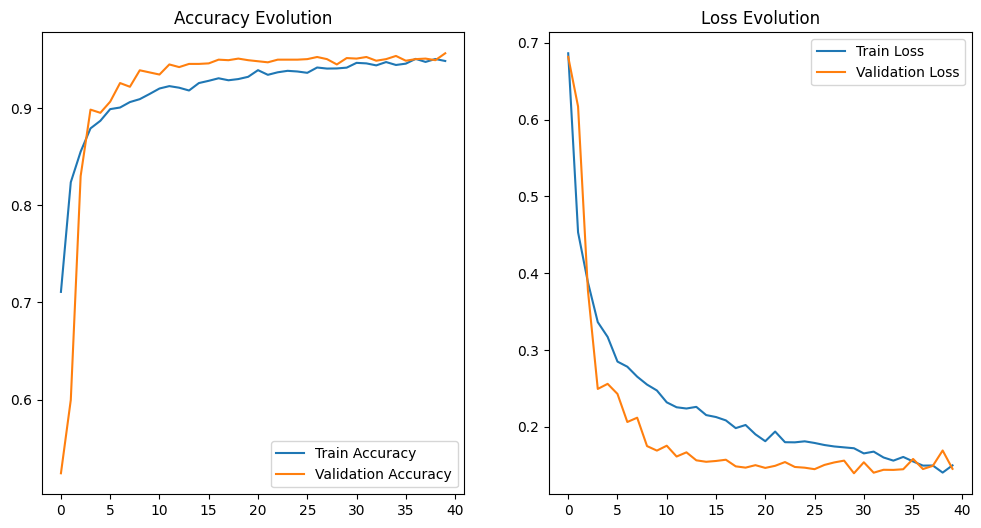

In [ ]:
# Étape 6: Évaluation du modèle
# ---------------------------------------------------
# Courbes d'apprentissage
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Evolution')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Evolution')
plt.legend()
plt.show()

In [ ]:
# Évaluation finale
y_pred = (model.predict(X_test) > 0.5).astype(int)
print(classification_report(y_test, y_pred))

72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
              precision    recall  f1-score   support

           0       0.95      0.94      0.94      1143
           1       0.94      0.95      0.94      1143

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286



72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step


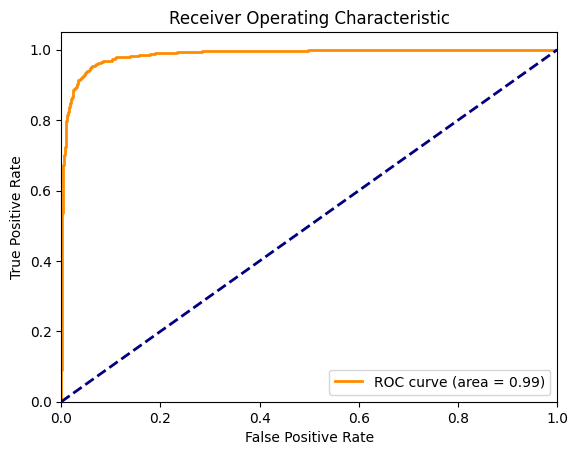

In [ ]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, model.predict(X_test))
roc_auc = auc(fpr, tpr)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()